# 📊 Análisis de Datos - Jugador 2 (Hipódromo Matemático)

Este notebook realiza un análisis completo y enfocado **exclusivamente en el JUGADOR 2**.

## Contenido
1. Carga y limpieza de datos (solo Jugador 2)
2. Análisis exploratorio
3. Rendimiento y evolución temporal
4. Análisis de dificultad y tipos de operaciones
5. Patrones de aprendizaje
6. Análisis de rachas y momentos
7. Visualizaciones avanzadas
8. Conclusiones y recomendaciones

In [22]:
# Importar librerías necesarias
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
from scipy import stats as scipy_stats
import warnings

warnings.filterwarnings('ignore')

# Configuración de visualización
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
%matplotlib inline

# Configuración de pandas
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:.2f}'.format)

print("✅ Librerías cargadas correctamente")

✅ Librerías cargadas correctamente


## 1. Carga y Limpieza de Datos (Solo Jugador 2)

In [23]:
# Conectar a la base de datos
DB_NAME = "estadisticas_juego.db"

try:
    conn = sqlite3.connect(DB_NAME)
    print(f"✅ Conexión exitosa a {DB_NAME}")
except Exception as e:
    print(f"❌ Error al conectar: {e}")
    raise

✅ Conexión exitosa a estadisticas_juego.db


In [24]:
# Cargar datos SOLO del JUGADOR 2
query = "SELECT * FROM operaciones WHERE jugador = 'JUGADOR 2'"
df = pd.read_sql_query(query, conn)

print("=" * 70)
print("🎯 ANÁLISIS EXCLUSIVO DEL JUGADOR 2")
print("=" * 70)
print(f"\n📊 Registros cargados: {len(df)}")
print(f"📅 Período: {df['timestamp'].min()} a {df['timestamp'].max()}")
print(f"👤 Jugador: {df['jugador'].unique()[0]}")

df

🎯 ANÁLISIS EXCLUSIVO DEL JUGADOR 2

📊 Registros cargados: 49
📅 Período: 2026-05-05 16:32:04 a 2026-05-13 17:30:27
👤 Jugador: JUGADOR 2


,id,jugador,operacion,respuesta_jugador,respuesta_correcta,es_correcta,dificultad,subzona,tiempo_ms,timestamp
0,2,JUGADOR 2,7.6 - 4.5,3.10,3.10,1,2,c,29383,2026-05-05 16:32:04
1,4,JUGADOR 2,1.97 - 0.471,2.74,1.50,0,0,a,50951,2026-05-05 16:32:55
2,5,JUGADOR 2,1.5 + 9.1,274.00,11.00,0,0,a,17241,2026-05-05 16:33:12
3,6,JUGADOR 2,5.9 - 2.1,2.74,3.80,0,0,a,15867,2026-05-05 16:33:28
4,7,JUGADOR 2,9.9 + 5.5,2.74,15.40,0,0,a,8513,2026-05-05 16:33:36
5,8,JUGADOR 2,6.0 + 2.3,8.30,8.30,1,0,a,26309,2026-05-05 16:34:03
6,9,JUGADOR 2,4.0 - 0.1,3.90,3.90,1,0,a,22649,2026-05-05 16:34:25
7,10,JUGADOR 2,7.8 - 3.3,4.50,4.50,1,0,a,20976,2026-05-05 16:35:20
8,12,JUGADOR 2,2.1 x 7,14.70,14.70,1,0,a,13313,2026-05-05 16:35:34
9,13,JUGADOR 2,9.6 - 1.6,8.00,8.00,1,0,a,22084,2026-05-05 16:35:56


In [25]:
# Información general del dataset
print("=" * 60)
print("INFORMACIÓN DEL DATASET")
print("=" * 60)
df.info()
print("\n" + "=" * 60)
print("ESTADÍSTICAS DESCRIPTIVAS")
print("=" * 60)
df.describe()

INFORMACIÓN DEL DATASET
<class 'pandas.DataFrame'>
RangeIndex: 49 entries, 0 to 48
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  49 non-null     int64  
 1   jugador             49 non-null     str    
 2   operacion           49 non-null     str    
 3   respuesta_jugador   49 non-null     float64
 4   respuesta_correcta  49 non-null     float64
 5   es_correcta         49 non-null     int64  
 6   dificultad          49 non-null     int64  
 7   subzona             49 non-null     str    
 8   tiempo_ms           49 non-null     int64  
 9   timestamp           49 non-null     str    
dtypes: float64(2), int64(4), str(4)
memory usage: 4.0 KB

ESTADÍSTICAS DESCRIPTIVAS


,id,respuesta_jugador,respuesta_correcta,es_correcta,dificultad,tiempo_ms
count,49.00,49.00,49.00,49.00,49.00,49.00
mean,36.18,24.58,12.41,0.65,1.14,29119.69
std,22.65,49.48,14.15,0.48,0.79,18863.06
min,2.00,0.00,0.50,0.00,0.00,8513.00
25%,16.00,3.90,4.00,0.00,1.00,15898.00
50%,34.00,8.00,7.00,1.00,1.00,22084.00
75%,60.00,18.04,14.70,1.00,2.00,34583.00
max,72.00,274.00,68.40,1.00,2.00,95003.00


In [26]:
# Limpieza de datos
print("🧹 Iniciando limpieza de datos...\n")

# 1. Convertir timestamp a datetime
df['timestamp'] = pd.to_datetime(df['timestamp'])
print("✓ Timestamps convertidos a datetime")

# 2. Verificar valores nulos
nulos = df.isnull().sum()
if nulos.sum() > 0:
    print(f"\n⚠️  Valores nulos encontrados:")
    print(nulos[nulos > 0])
    df = df.dropna()
    print(f"✓ Valores nulos eliminados. Registros restantes: {len(df)}")
else:
    print("✓ No se encontraron valores nulos")

# 3. Verificar duplicados
duplicados = df.duplicated().sum()
if duplicados > 0:
    print(f"\n⚠️  {duplicados} filas duplicadas encontradas")
    df = df.drop_duplicates()
    print(f"✓ Duplicados eliminados. Registros restantes: {len(df)}")
else:
    print("✓ No se encontraron duplicados")

# 4. Extraer tipo de operación
def extraer_tipo_operacion(operacion):
    if '+' in operacion:
        return 'Suma'
    elif '-' in operacion:
        return 'Resta'
    elif 'x' in operacion or '*' in operacion:
        return 'Multiplicación'
    elif '÷' in operacion or '/' in operacion:
        return 'División'
    else:
        return 'Desconocido'

df['tipo_operacion'] = df['operacion'].apply(extraer_tipo_operacion)
print("✓ Tipo de operación extraído")

# 5. Convertir tiempo a segundos
df['tiempo_segundos'] = df['tiempo_ms'] / 1000
print("✓ Tiempo convertido a segundos")

# 6. Añadir columnas de fecha
df['fecha'] = df['timestamp'].dt.date
df['hora'] = df['timestamp'].dt.hour
df['dia_semana'] = df['timestamp'].dt.day_name()
df['minuto'] = df['timestamp'].dt.minute
print("✓ Columnas temporales añadidas")

# Eliminamos los datos guardados en días que no se ha tenido clase
df = df[df['dia_semana'].isin(['Monday', 'Wednesday'])]
print("Se eliminan los datos que no se recojan en Lunes o Miércoles")

# # Eliminamos los datos en horarios fuera de clase
# df = df[df['hora']>17]
# print("Se eliminan los datos guardados antes de las 18:00")

# 7. Calcular error absoluto
df['error_absoluto'] = abs(df['respuesta_jugador'] - df['respuesta_correcta'])
df['error_relativo'] = (df['error_absoluto'] / df['respuesta_correcta'].abs()) * 100
df['error_relativo'] = df['error_relativo'].replace([np.inf, -np.inf], np.nan).fillna(0)
print("✓ Errores calculados")

# 8. Mapeo de dificultad
df['nivel_dificultad'] = df['subzona'].map({'a': 'Fácil', 'b': 'Medio', 'c': 'Difícil'})
print("✓ Nivel de dificultad mapeado")

# 9. Ordenar por timestamp
df = df.sort_values('timestamp').reset_index(drop=True)
df['num_operacion'] = range(1, len(df) + 1)
print("✓ Dataset ordenado cronológicamente")

# 10. Calcular rachas
df['racha'] = 0
racha_actual = 0
for i in range(len(df)):
    if df.loc[i, 'es_correcta']:
        racha_actual += 1
    else:
        racha_actual = 0
    df.loc[i, 'racha'] = racha_actual
print("✓ Rachas calculadas")

# 11. Detectar outliers en tiempo
Q1 = df['tiempo_segundos'].quantile(0.25)
Q3 = df['tiempo_segundos'].quantile(0.75)
IQR = Q3 - Q1
outliers_tiempo = df[(df['tiempo_segundos'] < (Q1 - 1.5 * IQR)) | 
                     (df['tiempo_segundos'] > (Q3 + 1.5 * IQR))]
print(f"\n⚠️  {len(outliers_tiempo)} outliers detectados en tiempo de respuesta")
df['es_outlier_tiempo'] = df.index.isin(outliers_tiempo.index)

print("\n✅ Limpieza completada")
print(f"\n📊 Dataset final: {len(df)} operaciones del Jugador 2, {len(df.columns)} columnas")

🧹 Iniciando limpieza de datos...

✓ Timestamps convertidos a datetime
✓ No se encontraron valores nulos
✓ No se encontraron duplicados
✓ Tipo de operación extraído
✓ Tiempo convertido a segundos
✓ Columnas temporales añadidas
Se eliminan los datos que no se recojan en Lunes o Miércoles
✓ Errores calculados
✓ Nivel de dificultad mapeado
✓ Dataset ordenado cronológicamente
✓ Rachas calculadas

⚠️  2 outliers detectados en tiempo de respuesta

✅ Limpieza completada

📊 Dataset final: 33 operaciones del Jugador 2, 22 columnas


In [27]:
# Vista del dataset limpio
print("Dataset limpio - Primeras filas:")
df

Dataset limpio - Primeras filas:


,id,jugador,operacion,respuesta_jugador,respuesta_correcta,es_correcta,dificultad,subzona,tiempo_ms,timestamp,tipo_operacion,tiempo_segundos,fecha,hora,dia_semana,minuto,error_absoluto,error_relativo,nivel_dificultad,num_operacion,racha,es_outlier_tiempo
0,20,JUGADOR 2,3.83 + 9.02,12.85,12.85,1,2,b,24114,2026-05-11 17:56:52,Suma,24.11,2026-05-11,17,Monday,56,0.00,0.00,Medio,1,1,False
1,21,JUGADOR 2,9.97 + 4.51,14.48,14.48,1,2,b,25410,2026-05-11 17:57:17,Suma,25.41,2026-05-11,17,Monday,57,0.00,0.00,Medio,2,2,False
2,25,JUGADOR 2,8.5 x 0.62,52.70,5.27,0,2,b,95003,2026-05-11 17:58:52,Multiplicación,95.00,2026-05-11,17,Monday,58,47.43,900.00,Medio,3,0,True
3,27,JUGADOR 2,9.66 - 3.61,6.05,6.05,1,2,b,21365,2026-05-11 18:01:22,Resta,21.36,2026-05-11,18,Monday,1,0.00,0.00,Medio,4,1,False
4,29,JUGADOR 2,1.2 x 5.3,6.36,6.36,1,2,b,34583,2026-05-11 18:01:57,Multiplicación,34.58,2026-05-11,18,Monday,1,0.00,0.00,Medio,5,2,False
5,31,JUGADOR 2,5.99 + 2.68,8.67,8.67,1,2,b,39141,2026-05-11 18:02:36,Suma,39.14,2026-05-11,18,Monday,2,0.00,0.00,Medio,6,3,False
6,32,JUGADOR 2,5.19 + 5.45,10.64,10.64,1,2,b,26611,2026-05-11 18:03:36,Suma,26.61,2026-05-11,18,Monday,3,0.00,0.00,Medio,7,4,False
7,33,JUGADOR 2,8.01 x 6.3,50.46,50.46,1,2,b,66434,2026-05-11 18:04:42,Multiplicación,66.43,2026-05-11,18,Monday,4,0.00,0.00,Medio,8,5,False
8,34,JUGADOR 2,73 ÷ 9,8.00,8.00,1,2,b,21873,2026-05-11 18:05:52,División,21.87,2026-05-11,18,Monday,5,0.00,0.00,Medio,9,6,False
9,35,JUGADOR 2,8.69 - 4.6,8.23,4.09,0,2,b,27810,2026-05-11 18:06:20,Resta,27.81,2026-05-11,18,Monday,6,4.14,101.22,Medio,10,0,False


## 2. Análisis Exploratorio del Jugador 2

In [28]:
# Resumen general del Jugador 2
print("=" * 70)
print("PERFIL COMPLETO DEL JUGADOR 2")
print("=" * 70)

total_operaciones = len(df)
total_correctas = df['es_correcta'].sum()
total_incorrectas = total_operaciones - total_correctas
precision_global = (total_correctas / total_operaciones * 100)

print(f"\n📊 ESTADÍSTICAS GENERALES:")
print(f"   • Operaciones totales: {total_operaciones:,}")
print(f"   • Respuestas correctas: {total_correctas:,} ({precision_global:.2f}%)")
print(f"   • Respuestas incorrectas: {total_incorrectas:,} ({100-precision_global:.2f}%)")

print(f"\n⏱️  TIEMPOS DE RESPUESTA:")
print(f"   • Promedio: {df['tiempo_segundos'].mean():.2f} segundos")
print(f"   • Mediana: {df['tiempo_segundos'].median():.2f} segundos")
print(f"   • Más rápido: {df['tiempo_segundos'].min():.2f} segundos")
print(f"   • Más lento: {df['tiempo_segundos'].max():.2f} segundos")
print(f"   • Desviación estándar: {df['tiempo_segundos'].std():.2f} segundos")

print(f"\n🎯 RACHAS:")
print(f"   • Racha máxima: {df['racha'].max()} aciertos consecutivos")
rachas_positivas = df[df['racha'] > 0]['racha']
if len(rachas_positivas) > 0:
    print(f"   • Racha promedio: {rachas_positivas.mean():.2f} aciertos")

print(f"\n📅 ACTIVIDAD:")
print(f"   • Días con actividad: {df['fecha'].nunique()}")
print(f"   • Primera sesión: {df['timestamp'].min()}")
print(f"   • Última sesión: {df['timestamp'].max()}")
dias_total = (df['timestamp'].max() - df['timestamp'].min()).days + 1
print(f"   • Período total: {dias_total} días")
print(f"   • Operaciones por día activo: {total_operaciones / df['fecha'].nunique():.1f}")

print(f"\n📚 NIVEL DE DIFICULTAD:")
for nivel in ['Fácil', 'Medio', 'Difícil']:
    count = len(df[df['nivel_dificultad'] == nivel])
    if count > 0:
        porcentaje = (count / total_operaciones) * 100
        print(f"   • {nivel}: {count} ops ({porcentaje:.1f}%)")

PERFIL COMPLETO DEL JUGADOR 2

📊 ESTADÍSTICAS GENERALES:
   • Operaciones totales: 33
   • Respuestas correctas: 22 (66.67%)
   • Respuestas incorrectas: 11 (33.33%)

⏱️  TIEMPOS DE RESPUESTA:
   • Promedio: 31.77 segundos
   • Mediana: 24.11 segundos
   • Más rápido: 11.76 segundos
   • Más lento: 95.00 segundos
   • Desviación estándar: 20.52 segundos

🎯 RACHAS:
   • Racha máxima: 6 aciertos consecutivos
   • Racha promedio: 2.68 aciertos

📅 ACTIVIDAD:
   • Días con actividad: 2
   • Primera sesión: 2026-05-11 17:56:52
   • Última sesión: 2026-05-13 17:30:27
   • Período total: 2 días
   • Operaciones por día activo: 16.5

📚 NIVEL DE DIFICULTAD:
   • Fácil: 15 ops (45.5%)
   • Medio: 18 ops (54.5%)


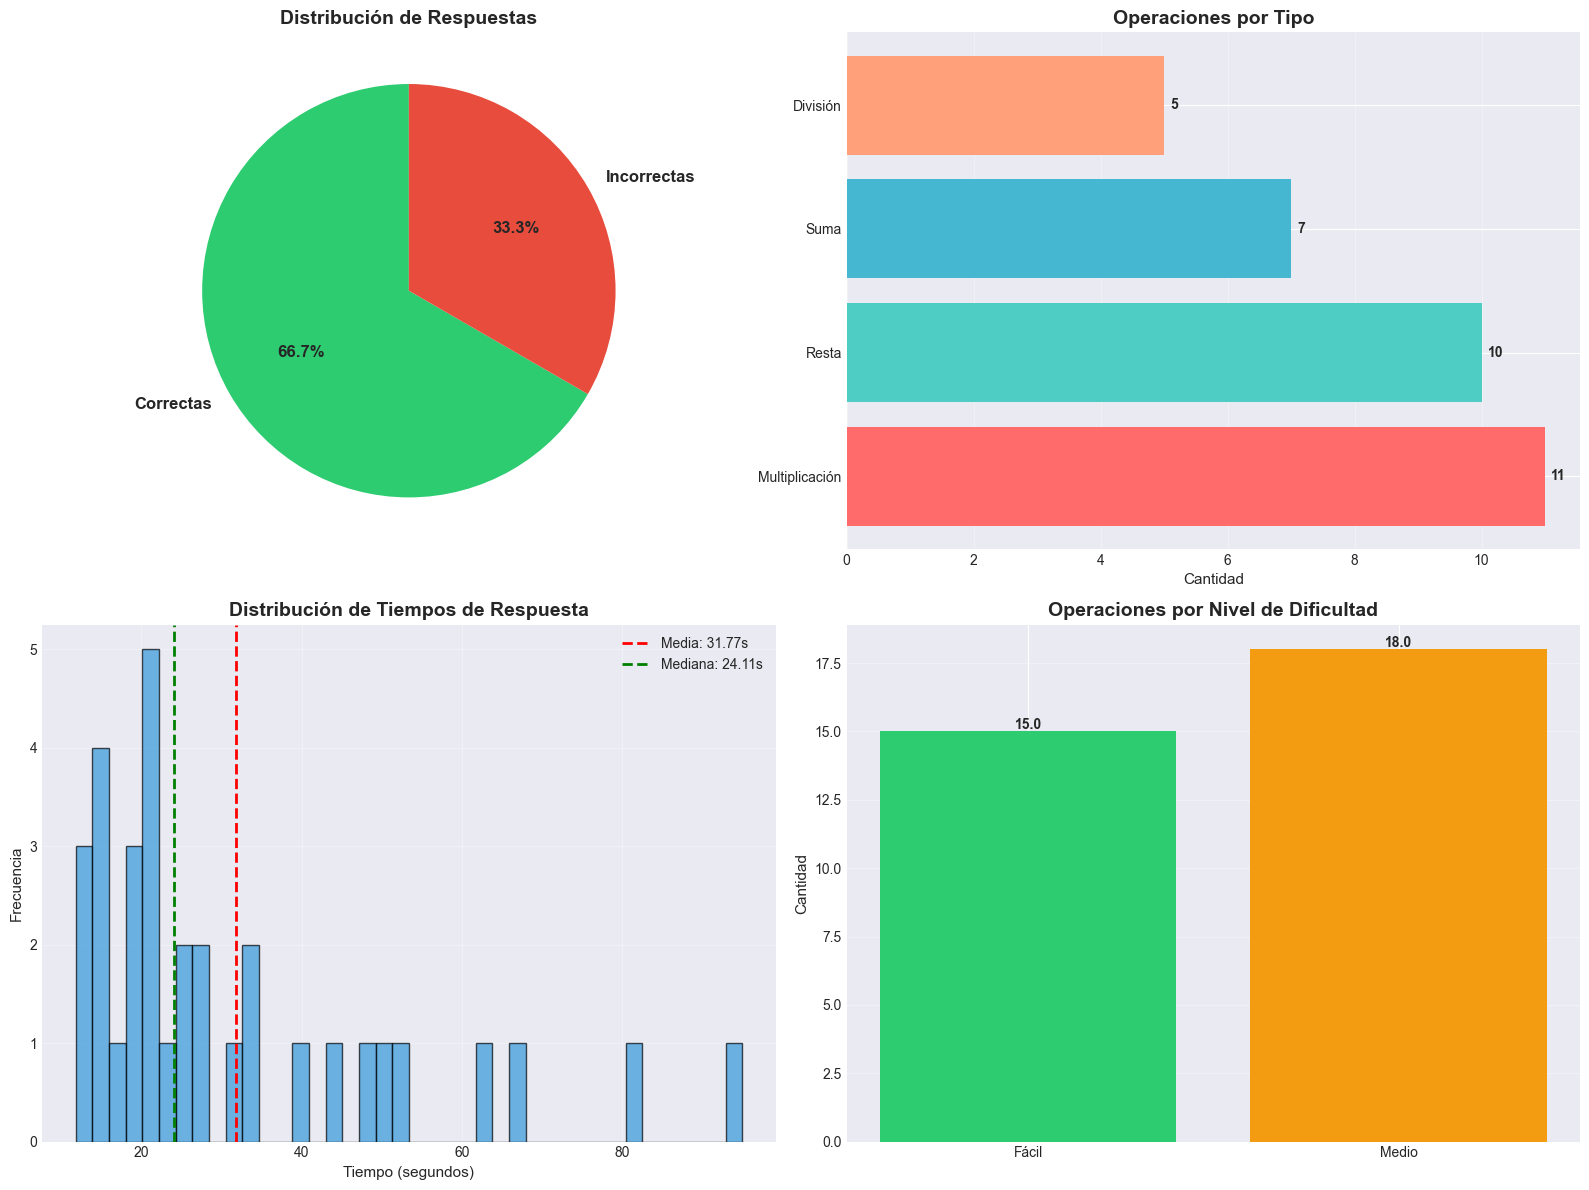

In [29]:
# Visualización del perfil general
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Distribución de resultados
resultados = df['es_correcta'].value_counts()
colors_resultado = ['#2ECC71', '#E74C3C']
axes[0, 0].pie(resultados.values, labels=['Correctas', 'Incorrectas'], autopct='%1.1f%%',
               startangle=90, colors=colors_resultado, textprops={'fontsize': 12, 'fontweight': 'bold'})
axes[0, 0].set_title('Distribución de Respuestas', fontsize=14, fontweight='bold')

# 2. Tipos de operaciones
tipo_counts = df['tipo_operacion'].value_counts()
axes[0, 1].barh(tipo_counts.index, tipo_counts.values, color=['#FF6B6B', '#4ECDC4', '#45B7D1', '#FFA07A'])
axes[0, 1].set_title('Operaciones por Tipo', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Cantidad', fontsize=11)
axes[0, 1].grid(axis='x', alpha=0.3)
for i, v in enumerate(tipo_counts.values):
    axes[0, 1].text(v + 0.1, i, str(v), va='center', fontweight='bold')

# 3. Histograma de tiempos
axes[1, 0].hist(df['tiempo_segundos'], bins=40, color='#3498DB', alpha=0.7, edgecolor='black')
axes[1, 0].axvline(df['tiempo_segundos'].mean(), color='red', linestyle='--', linewidth=2, 
                   label=f'Media: {df["tiempo_segundos"].mean():.2f}s')
axes[1, 0].axvline(df['tiempo_segundos'].median(), color='green', linestyle='--', linewidth=2, 
                   label=f'Mediana: {df["tiempo_segundos"].median():.2f}s')
axes[1, 0].set_title('Distribución de Tiempos de Respuesta', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('Tiempo (segundos)', fontsize=11)
axes[1, 0].set_ylabel('Frecuencia', fontsize=11)
axes[1, 0].legend(fontsize=10)
axes[1, 0].grid(alpha=0.3)

# 4. Niveles de dificultad
dif_counts = df['nivel_dificultad'].value_counts().reindex(['Fácil', 'Medio', 'Difícil'])
colors_dif = ['#2ECC71', '#F39C12', '#E74C3C']
axes[1, 1].bar(dif_counts.index, dif_counts.values, color=colors_dif)
axes[1, 1].set_title('Operaciones por Nivel de Dificultad', fontsize=14, fontweight='bold')
axes[1, 1].set_ylabel('Cantidad', fontsize=11)
axes[1, 1].grid(axis='y', alpha=0.3)
for i, v in enumerate(dif_counts.values):
    axes[1, 1].text(i, v + 0.1, str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

## 3. Evolución Temporal del Jugador 2

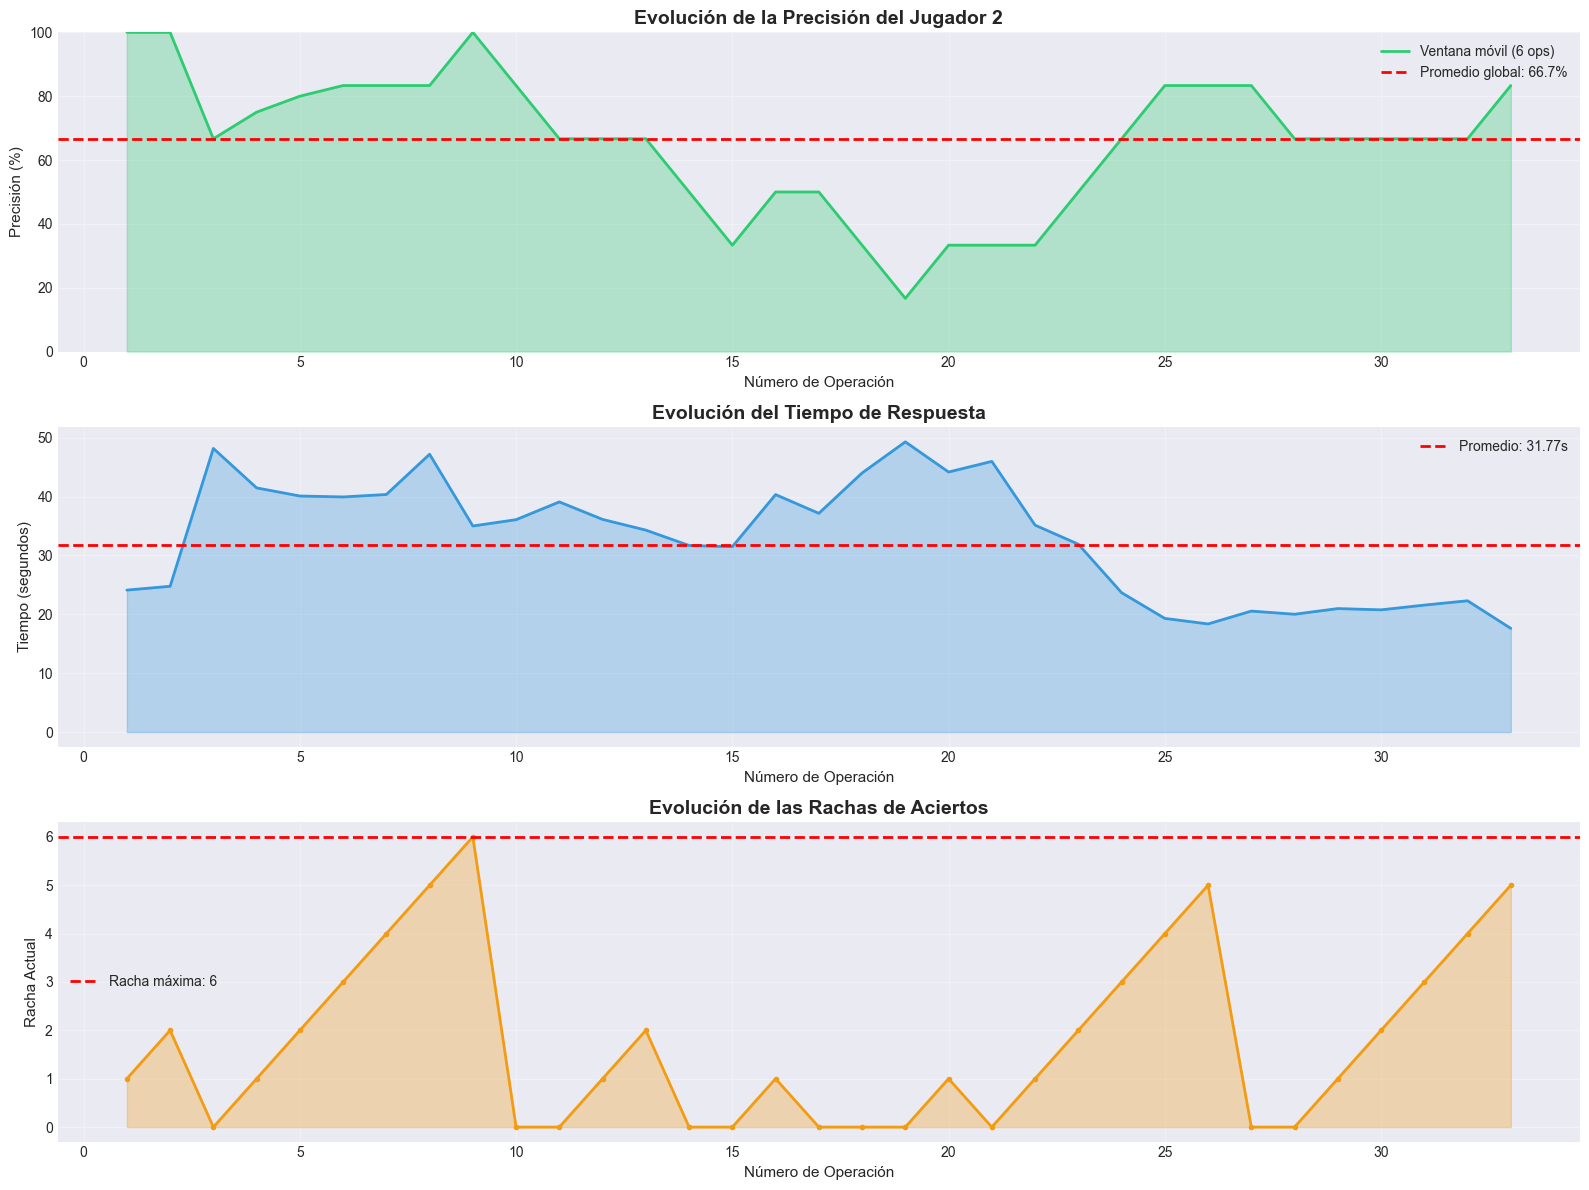

In [30]:
# Evolución de la precisión a lo largo del tiempo
fig, axes = plt.subplots(3, 1, figsize=(16, 12))

# 1. Precisión móvil
ventana = min(20, len(df) // 5)  # Ajustar ventana según cantidad de datos
df['precision_movil'] = df['es_correcta'].rolling(window=ventana, min_periods=1).mean() * 100

axes[0].plot(df['num_operacion'], df['precision_movil'], linewidth=2, color='#2ECC71', label=f'Ventana móvil ({ventana} ops)')
axes[0].axhline(y=precision_global, color='red', linestyle='--', linewidth=2, label=f'Promedio global: {precision_global:.1f}%')
axes[0].fill_between(df['num_operacion'], df['precision_movil'], alpha=0.3, color='#2ECC71')
axes[0].set_title('Evolución de la Precisión del Jugador 2', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Número de Operación', fontsize=11)
axes[0].set_ylabel('Precisión (%)', fontsize=11)
axes[0].set_ylim(0, 100)
axes[0].legend(fontsize=10)
axes[0].grid(alpha=0.3)

# 2. Tiempo de respuesta móvil
df['tiempo_movil'] = df['tiempo_segundos'].rolling(window=ventana, min_periods=1).mean()

axes[1].plot(df['num_operacion'], df['tiempo_movil'], linewidth=2, color='#3498DB')
axes[1].axhline(y=df['tiempo_segundos'].mean(), color='red', linestyle='--', linewidth=2, 
                label=f'Promedio: {df["tiempo_segundos"].mean():.2f}s')
axes[1].fill_between(df['num_operacion'], df['tiempo_movil'], alpha=0.3, color='#3498DB')
axes[1].set_title('Evolución del Tiempo de Respuesta', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Número de Operación', fontsize=11)
axes[1].set_ylabel('Tiempo (segundos)', fontsize=11)
axes[1].legend(fontsize=10)
axes[1].grid(alpha=0.3)

# 3. Rachas a lo largo del tiempo
axes[2].plot(df['num_operacion'], df['racha'], linewidth=2, color='#F39C12', marker='o', markersize=3)
axes[2].fill_between(df['num_operacion'], df['racha'], alpha=0.3, color='#F39C12')
axes[2].axhline(y=df['racha'].max(), color='red', linestyle='--', linewidth=2, 
                label=f'Racha máxima: {df["racha"].max()}')
axes[2].set_title('Evolución de las Rachas de Aciertos', fontsize=14, fontweight='bold')
axes[2].set_xlabel('Número de Operación', fontsize=11)
axes[2].set_ylabel('Racha Actual', fontsize=11)
axes[2].legend(fontsize=10)
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [31]:
# Análisis de tendencia: ¿está mejorando?
print("\n" + "=" * 70)
print("📈 ANÁLISIS DE TENDENCIA Y APRENDIZAJE")
print("=" * 70)

# Dividir en tres períodos
tercio = len(df) // 3
periodo1 = df.iloc[:tercio]
periodo2 = df.iloc[tercio:2*tercio]
periodo3 = df.iloc[2*tercio:]

print(f"\n📊 COMPARACIÓN POR PERÍODOS:")
print(f"\nPrimer tercio ({len(periodo1)} ops):")
print(f"   • Precisión: {periodo1['es_correcta'].mean()*100:.2f}%")
print(f"   • Tiempo medio: {periodo1['tiempo_segundos'].mean():.2f}s")

print(f"\nSegundo tercio ({len(periodo2)} ops):")
print(f"   • Precisión: {periodo2['es_correcta'].mean()*100:.2f}%")
print(f"   • Tiempo medio: {periodo2['tiempo_segundos'].mean():.2f}s")

print(f"\nTercer tercio ({len(periodo3)} ops):")
print(f"   • Precisión: {periodo3['es_correcta'].mean()*100:.2f}%")
print(f"   • Tiempo medio: {periodo3['tiempo_segundos'].mean():.2f}s")

mejora_precision = (periodo3['es_correcta'].mean() - periodo1['es_correcta'].mean()) * 100
mejora_tiempo = periodo1['tiempo_segundos'].mean() - periodo3['tiempo_segundos'].mean()

print(f"\n💡 CAMBIOS OBSERVADOS:")
print(f"   • Cambio en precisión: {mejora_precision:+.2f} puntos porcentuales")
print(f"   • Cambio en tiempo: {mejora_tiempo:+.2f} segundos")

if mejora_precision > 5:
    print(f"   ✅ ¡Mejora significativa en precisión!")
elif mejora_precision < -5:
    print(f"   ⚠️  Disminución en precisión")
else:
    print(f"   → Precisión estable")

if mejora_tiempo > 1:
    print(f"   ✅ ¡Respondiendo más rápido!")
elif mejora_tiempo < -1:
    print(f"   ⚠️  Respondiendo más lento")
else:
    print(f"   → Tiempo estable")


📈 ANÁLISIS DE TENDENCIA Y APRENDIZAJE

📊 COMPARACIÓN POR PERÍODOS:

Primer tercio (11 ops):
   • Precisión: 72.73%
   • Tiempo medio: 39.55s

Segundo tercio (11 ops):
   • Precisión: 45.45%
   • Tiempo medio: 36.38s

Tercer tercio (11 ops):
   • Precisión: 81.82%
   • Tiempo medio: 19.37s

💡 CAMBIOS OBSERVADOS:
   • Cambio en precisión: +9.09 puntos porcentuales
   • Cambio en tiempo: +20.18 segundos
   ✅ ¡Mejora significativa en precisión!
   ✅ ¡Respondiendo más rápido!


## 4. Análisis por Tipo de Operación

In [32]:
# Estadísticas por tipo de operación
stats_operacion = df.groupby('tipo_operacion').agg({
    'id': 'count',
    'es_correcta': ['sum', 'mean'],
    'tiempo_segundos': ['mean', 'std'],
    'error_absoluto': 'mean'
}).round(2)

stats_operacion.columns = ['Total', 'Correctas', 'Precisión', 'Tiempo_Medio', 'Desv_Tiempo', 'Error_Medio']
stats_operacion['Precisión'] = stats_operacion['Precisión'] * 100
stats_operacion = stats_operacion.sort_values('Precisión', ascending=False)

print("\n" + "=" * 80)
print("📊 RENDIMIENTO POR TIPO DE OPERACIÓN")
print("=" * 80)
print(stats_operacion)

# Identificar fortalezas y debilidades
mejor_op = stats_operacion['Precisión'].idxmax()
peor_op = stats_operacion['Precisión'].idxmin()

print(f"\n💪 FORTALEZA: {mejor_op} ({stats_operacion.loc[mejor_op, 'Precisión']:.1f}% precisión)")
print(f"🎯 ÁREA DE MEJORA: {peor_op} ({stats_operacion.loc[peor_op, 'Precisión']:.1f}% precisión)")


📊 RENDIMIENTO POR TIPO DE OPERACIÓN
                Total  Correctas  Precisión  Tiempo_Medio  Desv_Tiempo  \
tipo_operacion                                                           
Suma                7          6      86.00         24.71         7.33   
Resta              10          8      80.00         21.86        11.42   
Multiplicación     11          7      64.00         39.88        28.63   
División            5          1      20.00         43.59        16.01   

                Error_Medio  
tipo_operacion               
Suma                   0.93  
Resta                  0.74  
Multiplicación         4.40  
División               7.00  

💪 FORTALEZA: Suma (86.0% precisión)
🎯 ÁREA DE MEJORA: División (20.0% precisión)


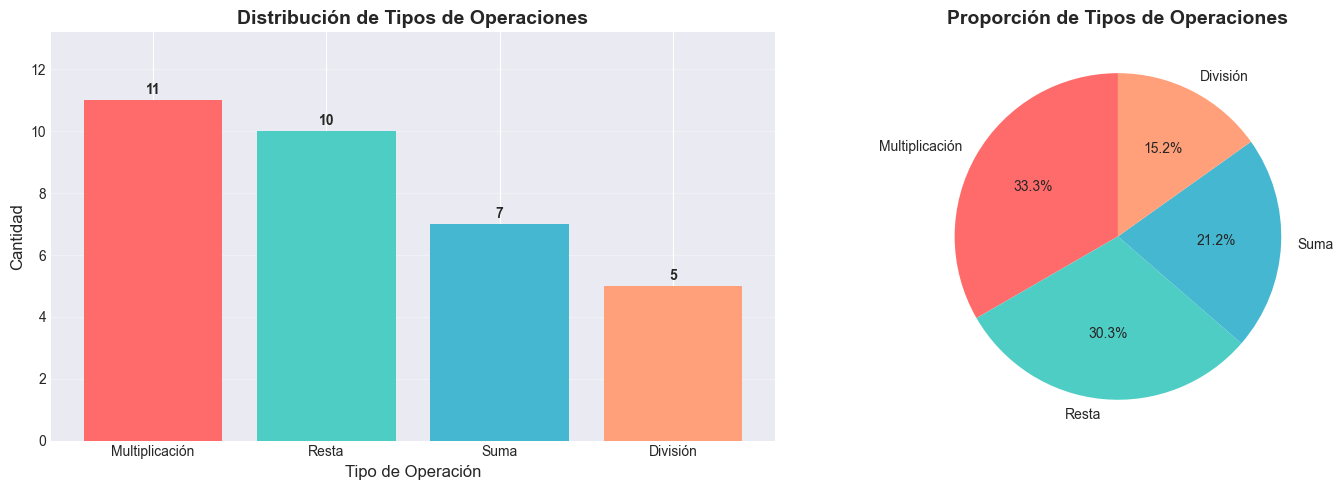

In [33]:
# Distribución de tipos de operaciones
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Gráfico de barras
tipo_counts = df['tipo_operacion'].value_counts()
axes[0].bar(tipo_counts.index, tipo_counts.values, color=['#FF6B6B', '#4ECDC4', '#45B7D1', '#FFA07A'])
axes[0].set_title('Distribución de Tipos de Operaciones', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Cantidad', fontsize=12)
axes[0].set_xlabel('Tipo de Operación', fontsize=12)
axes[0].grid(axis='y', alpha=0.3)

for i, v in enumerate(tipo_counts.values):
    # Usamos un pequeño margen (0.1 en lugar de 10)
    axes[0].text(i, v + 0.1, str(v), ha='center', va='bottom', fontweight='bold')

# Opcional: Ajustar el límite de Y para que el texto no se corte
axes[0].set_ylim(0, max(tipo_counts.values) * 1.2)

# Gráfico de pastel
axes[1].pie(tipo_counts.values, labels=tipo_counts.index, autopct='%1.1f%%',
            startangle=90, colors=['#FF6B6B', '#4ECDC4', '#45B7D1', '#FFA07A'])
axes[1].set_title('Proporción de Tipos de Operaciones', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

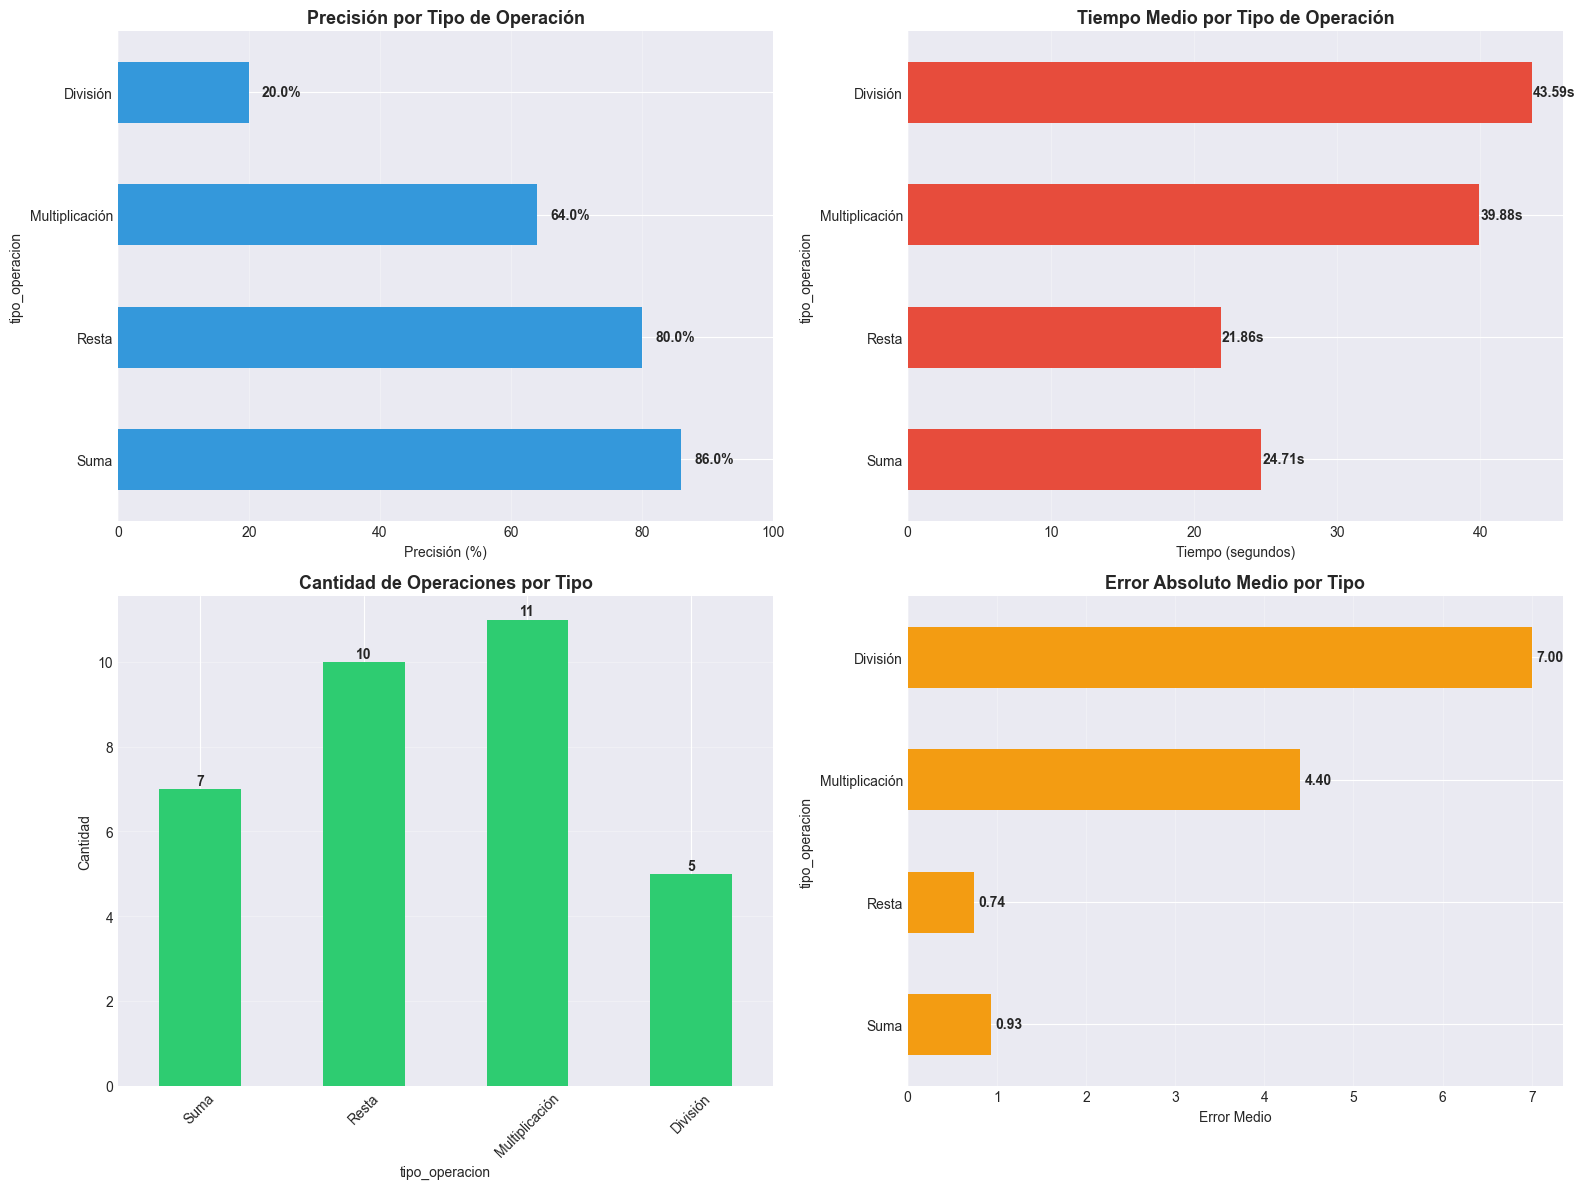

In [34]:
# Visualización comparativa por operación
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Precisión por tipo
stats_operacion['Precisión'].plot(kind='barh', ax=axes[0, 0], color='#3498DB')
axes[0, 0].set_title('Precisión por Tipo de Operación', fontsize=13, fontweight='bold')
axes[0, 0].set_xlabel('Precisión (%)')
axes[0, 0].set_xlim(0, 100)
axes[0, 0].grid(axis='x', alpha=0.3)
for i, v in enumerate(stats_operacion['Precisión']):
    axes[0, 0].text(v + 2, i, f'{v:.1f}%', va='center', fontweight='bold')

# 2. Tiempo por tipo
stats_operacion['Tiempo_Medio'].plot(kind='barh', ax=axes[0, 1], color='#E74C3C')
axes[0, 1].set_title('Tiempo Medio por Tipo de Operación', fontsize=13, fontweight='bold')
axes[0, 1].set_xlabel('Tiempo (segundos)')
axes[0, 1].grid(axis='x', alpha=0.3)
for i, v in enumerate(stats_operacion['Tiempo_Medio']):
    axes[0, 1].text(v + 0.1, i, f'{v:.2f}s', va='center', fontweight='bold')

# 3. Cantidad por tipo
stats_operacion['Total'].plot(kind='bar', ax=axes[1, 0], color='#2ECC71')
axes[1, 0].set_title('Cantidad de Operaciones por Tipo', fontsize=13, fontweight='bold')
axes[1, 0].set_ylabel('Cantidad')
axes[1, 0].tick_params(axis='x', rotation=45)
axes[1, 0].grid(axis='y', alpha=0.3)
for i, v in enumerate(stats_operacion['Total']):
    axes[1, 0].text(i, v + 0.1, str(v), ha='center', fontweight='bold')

# 4. Error medio por tipo
stats_operacion['Error_Medio'].plot(kind='barh', ax=axes[1, 1], color='#F39C12')
axes[1, 1].set_title('Error Absoluto Medio por Tipo', fontsize=13, fontweight='bold')
axes[1, 1].set_xlabel('Error Medio')
axes[1, 1].grid(axis='x', alpha=0.3)
for i, v in enumerate(stats_operacion['Error_Medio']):
    axes[1, 1].text(v + 0.05, i, f'{v:.2f}', va='center', fontweight='bold')

plt.tight_layout()
plt.show()

## 5. Análisis por Nivel de Dificultad


📚 RENDIMIENTO POR NIVEL DE DIFICULTAD
                  Total  Correctas  Precisión  Tiempo_Medio  Desv_Tiempo  \
nivel_dificultad                                                           
Fácil             15.00      11.00      73.00         21.86        11.15   
Medio             18.00      11.00      61.00         40.02        23.05   
Difícil             NaN        NaN        NaN           NaN          NaN   

                  Error_Medio  Racha_Max  
nivel_dificultad                          
Fácil                    2.20       5.00  
Medio                    3.57       6.00  
Difícil                   NaN        NaN  


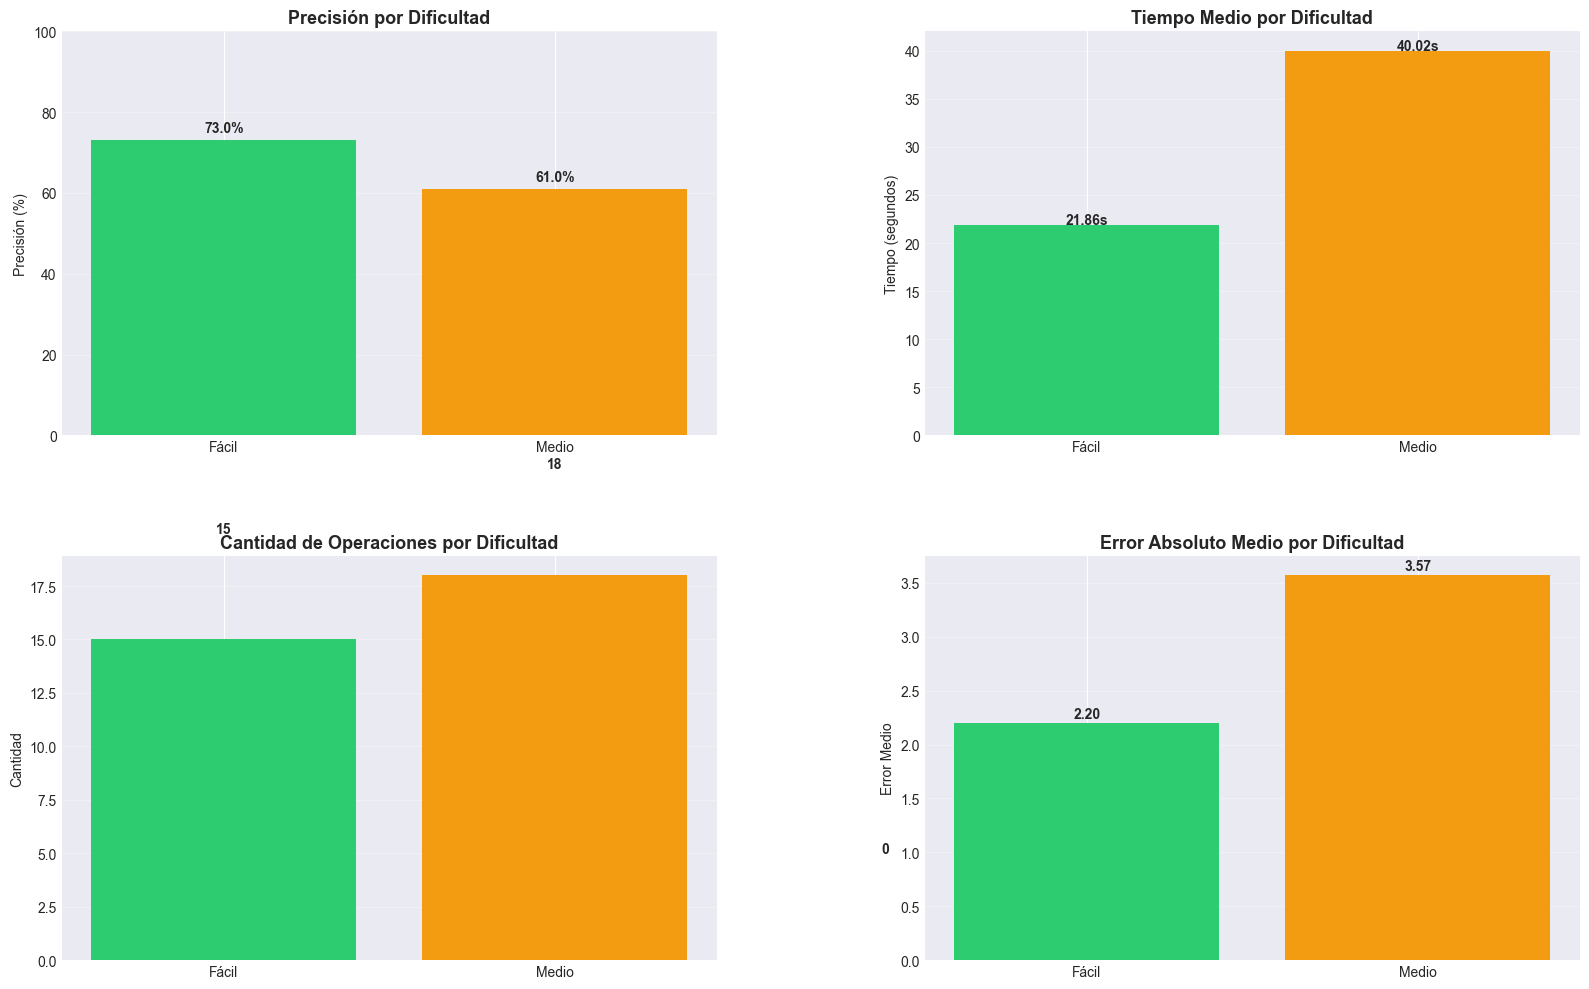

In [35]:
# Estadísticas por nivel de dificultad
stats_dificultad = df.groupby('nivel_dificultad').agg({
    'id': 'count',
    'es_correcta': ['sum', 'mean'],
    'tiempo_segundos': ['mean', 'std'],
    'error_absoluto': 'mean',
    'racha': 'max'
}).round(2)

stats_dificultad.columns = ['Total', 'Correctas', 'Precisión', 'Tiempo_Medio', 'Desv_Tiempo', 'Error_Medio', 'Racha_Max']
stats_dificultad['Precisión'] = stats_dificultad['Precisión'] * 100

# Ordenar por dificultad
orden_dificultad = ['Fácil', 'Medio', 'Difícil']
stats_dificultad = stats_dificultad.reindex(orden_dificultad)

print("\n" + "=" * 70)
print("📚 RENDIMIENTO POR NIVEL DE DIFICULTAD")
print("=" * 70)
print(stats_dificultad)

# Visualización
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

colors = ['#2ECC71', '#F39C12', '#E74C3C']

# 1. Precisión
axes[0, 0].bar(stats_dificultad.index, stats_dificultad['Precisión'], color=colors)
axes[0, 0].set_title('Precisión por Dificultad', fontsize=13, fontweight='bold')
axes[0, 0].set_ylabel('Precisión (%)')
axes[0, 0].set_ylim(0, 100)
axes[0, 0].grid(axis='y', alpha=0.3)
for i, v in enumerate(stats_dificultad['Precisión']):
    axes[0, 0].text(i, v + 2, f'{v:.1f}%', ha='center', fontweight='bold')

# 2. Tiempo medio
axes[0, 1].bar(stats_dificultad.index, stats_dificultad['Tiempo_Medio'], color=colors)
axes[0, 1].set_title('Tiempo Medio por Dificultad', fontsize=13, fontweight='bold')
axes[0, 1].set_ylabel('Tiempo (segundos)')
axes[0, 1].grid(axis='y', alpha=0.3)
for i, v in enumerate(stats_dificultad['Tiempo_Medio']):
    axes[0, 1].text(i, v + 0.1, f'{v:.2f}s', ha='center', fontweight='bold')

# 3. Cantidad de operaciones
axes[1, 0].bar(stats_dificultad.index, stats_dificultad['Total'], color=colors)
axes[1, 0].set_title('Cantidad de Operaciones por Dificultad', fontsize=13, fontweight='bold')
axes[1, 0].set_ylabel('Cantidad')
axes[1, 0].grid(axis='y', alpha=0.3)
for i, v in enumerate(stats_dificultad['Total']):
    y = v + 5 if pd.notna(v) else 5
    label = str(int(v)) if pd.notna(v) else "0"
    axes[1, 0].text(i, y, label, ha='center', fontweight='bold')

# 4. Error medio
axes[1, 1].bar(stats_dificultad.index, stats_dificultad['Error_Medio'], color=colors)
axes[1, 1].set_title('Error Absoluto Medio por Dificultad', fontsize=13, fontweight='bold')
axes[1, 1].set_ylabel('Error Medio')
axes[1, 1].grid(axis='y', alpha=0.3)
for i, v in enumerate(stats_dificultad['Error_Medio']):
    axes[1, 1].text(i, v + 0.05, f'{v:.2f}', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

## 6. Patrones Temporales


⏰ ACTIVIDAD POR HORA DEL DÍA
      Operaciones  Precisión  Tiempo_Medio
hora                                      
17             20      65.00         28.42
18             13      69.00         36.91

🏆 Mejor rendimiento: 18:00h (69.0% precisión)
📉 Menor rendimiento: 17:00h (65.0% precisión)
🔥 Hora más activa: 17:00h (20 ops)


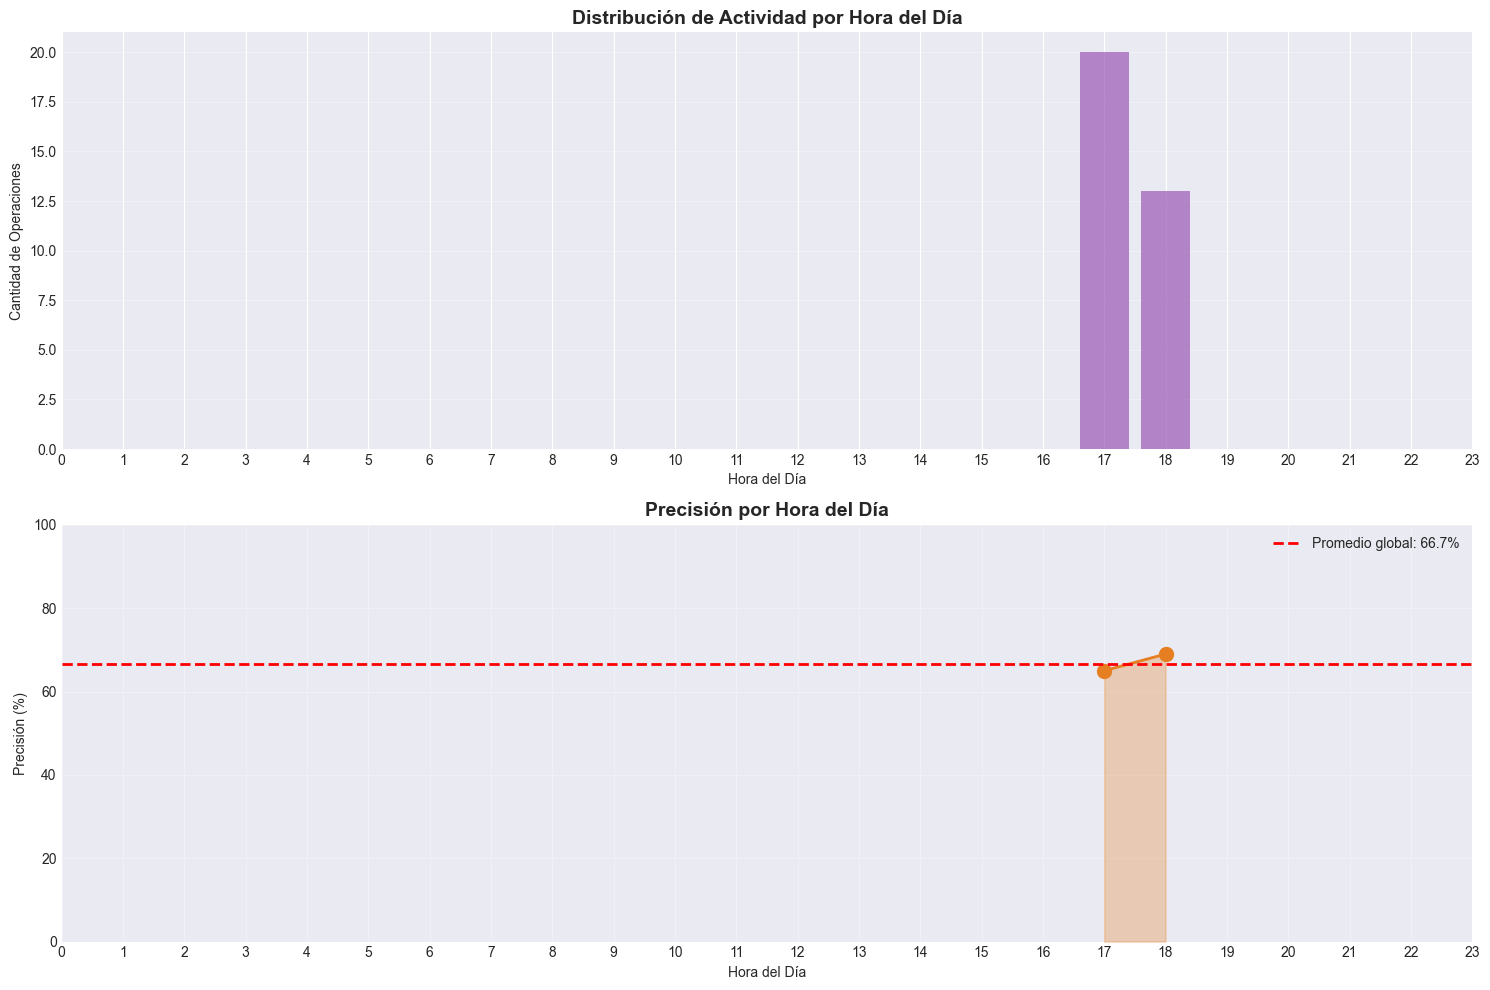

In [36]:
# Análisis por hora del día
actividad_horaria = df.groupby('hora').agg({
    'id': 'count',
    'es_correcta': 'mean',
    'tiempo_segundos': 'mean'
}).round(2)

actividad_horaria.columns = ['Operaciones', 'Precisión', 'Tiempo_Medio']
actividad_horaria['Precisión'] = actividad_horaria['Precisión'] * 100

print("\n⏰ ACTIVIDAD POR HORA DEL DÍA")
print("=" * 60)
print(actividad_horaria)

# Encontrar mejor y peor hora
if len(actividad_horaria) > 0:
    mejor_hora = actividad_horaria['Precisión'].idxmax()
    peor_hora = actividad_horaria['Precisión'].idxmin()
    hora_mas_activa = actividad_horaria['Operaciones'].idxmax()
    
    print(f"\n🏆 Mejor rendimiento: {mejor_hora}:00h ({actividad_horaria.loc[mejor_hora, 'Precisión']:.1f}% precisión)")
    print(f"📉 Menor rendimiento: {peor_hora}:00h ({actividad_horaria.loc[peor_hora, 'Precisión']:.1f}% precisión)")
    print(f"🔥 Hora más activa: {hora_mas_activa}:00h ({int(actividad_horaria.loc[hora_mas_activa, 'Operaciones'])} ops)")

# Visualización
fig, axes = plt.subplots(2, 1, figsize=(15, 10))

# Operaciones por hora
axes[0].bar(actividad_horaria.index, actividad_horaria['Operaciones'], color='#9B59B6', alpha=0.7)
axes[0].set_title('Distribución de Actividad por Hora del Día', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Hora del Día')
axes[0].set_ylabel('Cantidad de Operaciones')
axes[0].grid(axis='y', alpha=0.3)
axes[0].set_xticks(range(24))

# Precisión por hora
axes[1].plot(actividad_horaria.index, actividad_horaria['Precisión'], 
             marker='o', linewidth=2, markersize=10, color='#E67E22')
axes[1].fill_between(actividad_horaria.index, actividad_horaria['Precisión'], alpha=0.3, color='#E67E22')
axes[1].axhline(y=precision_global, color='red', linestyle='--', linewidth=2, 
                label=f'Promedio global: {precision_global:.1f}%')
axes[1].set_title('Precisión por Hora del Día', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Hora del Día')
axes[1].set_ylabel('Precisión (%)')
axes[1].set_ylim(0, 100)
axes[1].legend(fontsize=10)
axes[1].grid(alpha=0.3)
axes[1].set_xticks(range(24))

plt.tight_layout()
plt.show()


📅 RESUMEN DIARIO
            Operaciones  Precisión  Tiempo_Medio  Mejor_Racha
fecha                                                        
2026-05-11           16      69.00         39.02            6
2026-05-13           17      65.00         24.94            5


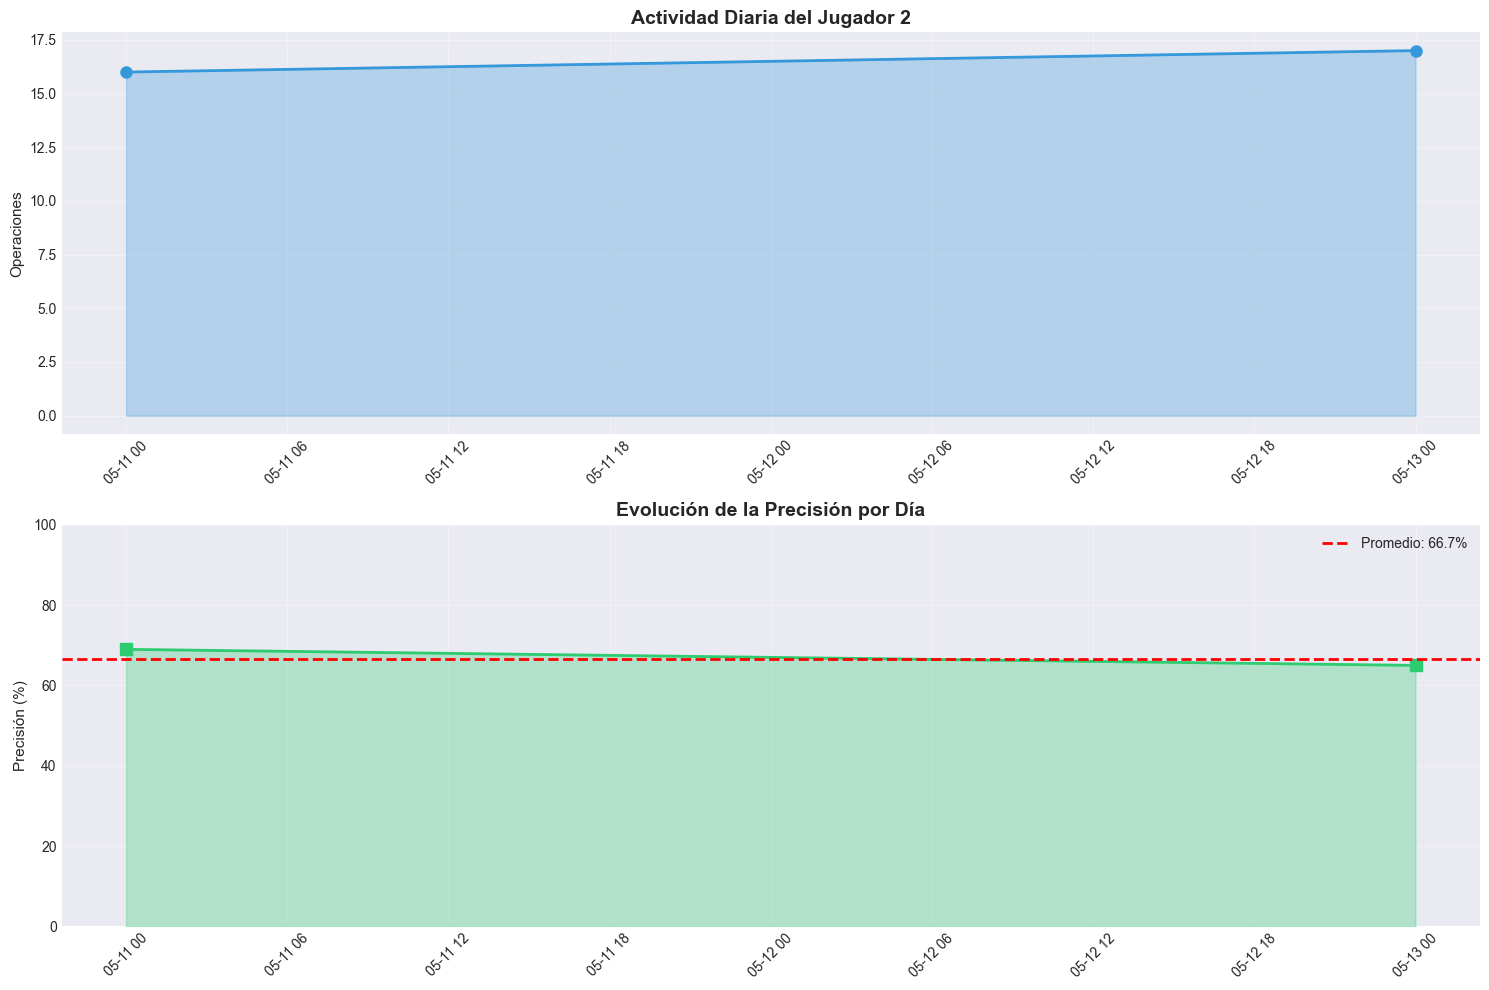

In [37]:
# Análisis por día
actividad_diaria = df.groupby('fecha').agg({
    'id': 'count',
    'es_correcta': 'mean',
    'tiempo_segundos': 'mean',
    'racha': 'max'
}).round(2)

actividad_diaria.columns = ['Operaciones', 'Precisión', 'Tiempo_Medio', 'Mejor_Racha']
actividad_diaria['Precisión'] = actividad_diaria['Precisión'] * 100

print("\n📅 RESUMEN DIARIO")
print("=" * 70)
print(actividad_diaria)

# Gráficos de evolución diaria
fig, axes = plt.subplots(2, 1, figsize=(15, 10))

# Operaciones por día
axes[0].plot(actividad_diaria.index, actividad_diaria['Operaciones'], 
             marker='o', linewidth=2, markersize=8, color='#3498DB')
axes[0].fill_between(actividad_diaria.index, actividad_diaria['Operaciones'], alpha=0.3, color='#3498DB')
axes[0].set_title('Actividad Diaria del Jugador 2', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Operaciones', fontsize=11)
axes[0].grid(alpha=0.3)
axes[0].tick_params(axis='x', rotation=45)

# Precisión por día
axes[1].plot(actividad_diaria.index, actividad_diaria['Precisión'], 
             marker='s', linewidth=2, markersize=8, color='#2ECC71')
axes[1].fill_between(actividad_diaria.index, actividad_diaria['Precisión'], alpha=0.3, color='#2ECC71')
axes[1].axhline(y=precision_global, color='red', linestyle='--', linewidth=2, 
                label=f'Promedio: {precision_global:.1f}%')
axes[1].set_title('Evolución de la Precisión por Día', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Precisión (%)', fontsize=11)
axes[1].set_ylim(0, 100)
axes[1].legend(fontsize=10)
axes[1].grid(alpha=0.3)
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

## 7. Análisis Avanzado: Correlaciones y Patrones

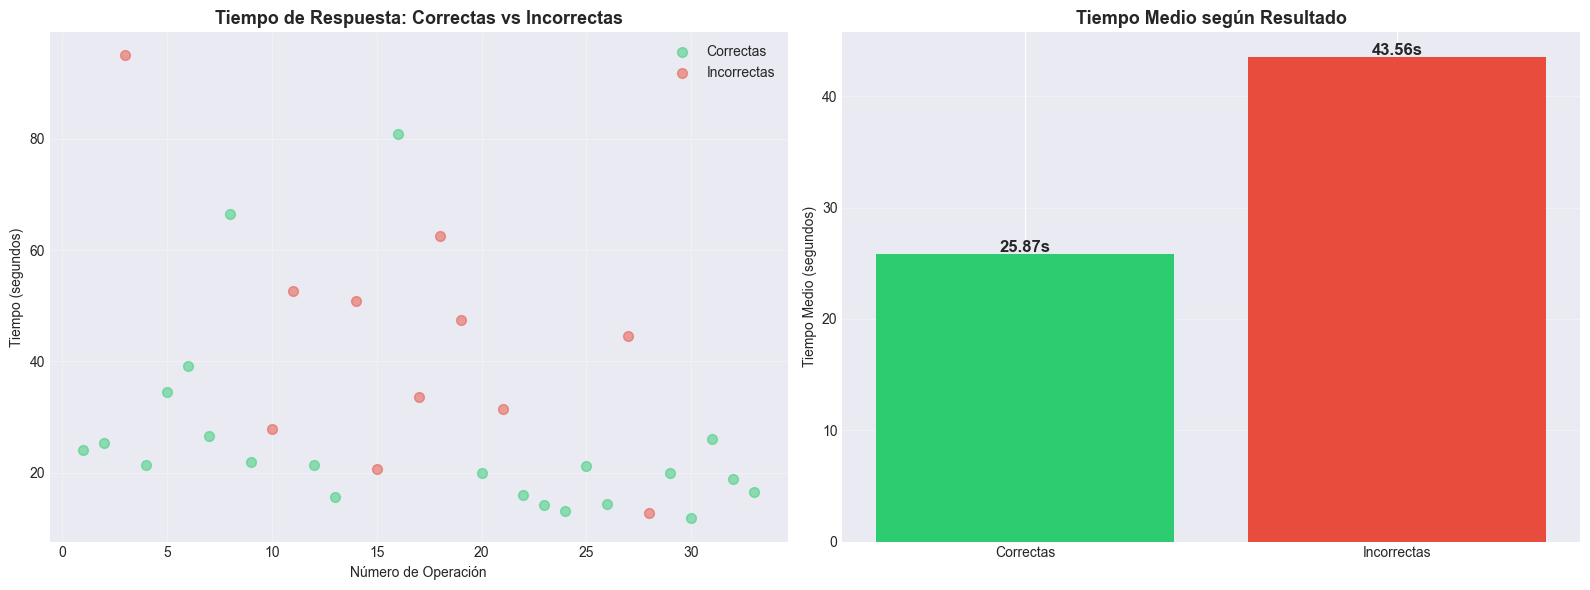


⏱️  ANÁLISIS DE TIEMPOS:
   • Tiempo medio en correctas: 25.87s
   • Tiempo medio en incorrectas: 43.56s
   • Diferencia: 17.70s
   💡 Insight: Las respuestas incorrectas toman más tiempo (posible indecisión)


In [38]:
# Relación entre tiempo y resultado
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Scatter plot
correctas = df[df['es_correcta'] == 1]
incorrectas = df[df['es_correcta'] == 0]

axes[0].scatter(correctas['num_operacion'], correctas['tiempo_segundos'], 
               alpha=0.5, s=50, color='#2ECC71', label='Correctas')
axes[0].scatter(incorrectas['num_operacion'], incorrectas['tiempo_segundos'], 
               alpha=0.5, s=50, color='#E74C3C', label='Incorrectas')
axes[0].set_title('Tiempo de Respuesta: Correctas vs Incorrectas', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Número de Operación')
axes[0].set_ylabel('Tiempo (segundos)')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Comparación de tiempos
tiempo_correctas = correctas['tiempo_segundos'].mean()
tiempo_incorrectas = incorrectas['tiempo_segundos'].mean()

axes[1].bar(['Correctas', 'Incorrectas'], [tiempo_correctas, tiempo_incorrectas],
           color=['#2ECC71', '#E74C3C'])
axes[1].set_title('Tiempo Medio según Resultado', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Tiempo Medio (segundos)')
axes[1].grid(axis='y', alpha=0.3)

for i, v in enumerate([tiempo_correctas, tiempo_incorrectas]):
    axes[1].text(i, v + 0.1, f'{v:.2f}s', ha='center', fontweight='bold', fontsize=12)

plt.tight_layout()
plt.show()

print(f"\n⏱️  ANÁLISIS DE TIEMPOS:")
print(f"   • Tiempo medio en correctas: {tiempo_correctas:.2f}s")
print(f"   • Tiempo medio en incorrectas: {tiempo_incorrectas:.2f}s")
print(f"   • Diferencia: {abs(tiempo_correctas - tiempo_incorrectas):.2f}s")

if tiempo_incorrectas > tiempo_correctas:
    print(f"   💡 Insight: Las respuestas incorrectas toman más tiempo (posible indecisión)")
else:
    print(f"   💡 Insight: Las respuestas rápidas no garantizan precisión")


📈 MATRIZ DE CORRELACIÓN
                 tiempo_segundos  es_correcta  dificultad  error_absoluto  \
tiempo_segundos             1.00        -0.41        0.45            0.55   
es_correcta                -0.41         1.00       -0.13           -0.43   
dificultad                  0.45        -0.13        1.00            0.07   
error_absoluto              0.55        -0.43        0.07            1.00   
racha                      -0.29         0.70       -0.14           -0.30   

                 racha  
tiempo_segundos  -0.29  
es_correcta       0.70  
dificultad       -0.14  
error_absoluto   -0.30  
racha             1.00  


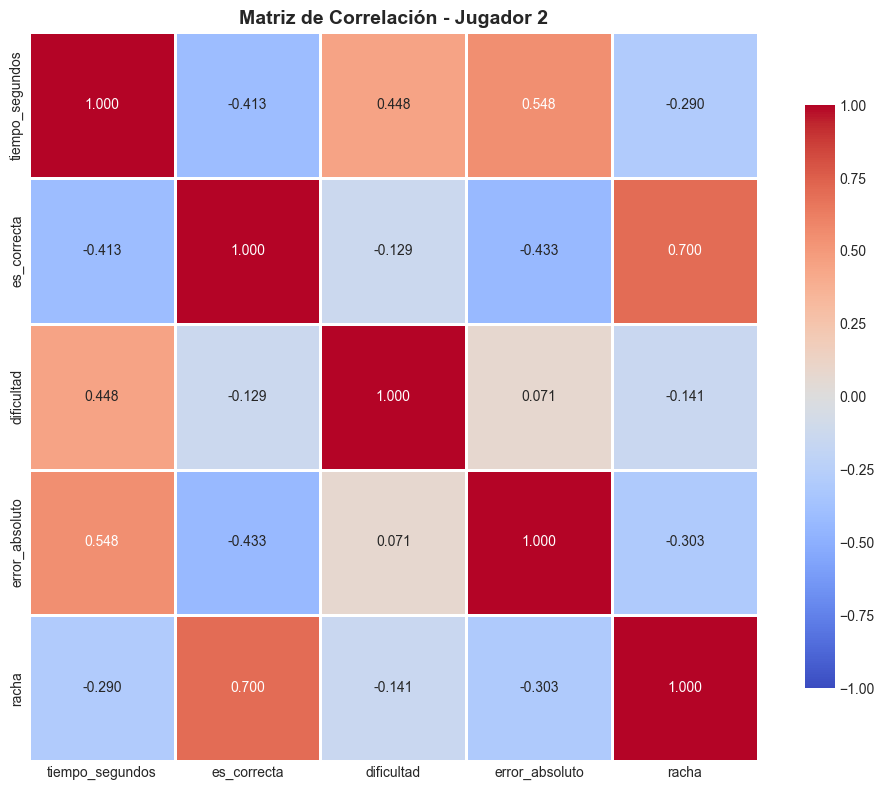


💡 INSIGHTS DE CORRELACIONES:
   • Respuestas más lentas tienden a ser incorrectas
   • La dificultad afecta negativamente la precisión
   • El momento (rachas) mejora la velocidad de respuesta


In [39]:
# Análisis de correlaciones
variables_numericas = ['tiempo_segundos', 'es_correcta', 'dificultad', 'error_absoluto', 'racha']
correlacion = df[variables_numericas].corr()

print("\n📈 MATRIZ DE CORRELACIÓN")
print("=" * 60)
print(correlacion.round(3))

# Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlacion, annot=True, fmt='.3f', cmap='coolwarm', center=0,
            square=True, linewidths=1, cbar_kws={"shrink": 0.8},
            vmin=-1, vmax=1)
plt.title('Matriz de Correlación - Jugador 2', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Interpretación de correlaciones significativas
print("\n💡 INSIGHTS DE CORRELACIONES:")
if correlacion.loc['tiempo_segundos', 'es_correcta'] < -0.1:
    print("   • Respuestas más lentas tienden a ser incorrectas")
elif correlacion.loc['tiempo_segundos', 'es_correcta'] > 0.1:
    print("   • Respuestas más lentas tienden a ser correctas (reflexión)")
    
if correlacion.loc['dificultad', 'es_correcta'] < -0.1:
    print("   • La dificultad afecta negativamente la precisión")
    
if correlacion.loc['racha', 'tiempo_segundos'] < -0.1:
    print("   • El momento (rachas) mejora la velocidad de respuesta")

## 8. Resumen Ejecutivo y Recomendaciones

In [40]:
print("\n" + "="*80)
print("🎯 INFORME COMPLETO DEL JUGADOR 2")
print("="*80)

print(f"\n📊 RESUMEN GENERAL:")
print(f"   • Total de operaciones: {len(df):,}")
print(f"   • Precisión global: {precision_global:.2f}%")
print(f"   • Tiempo medio de respuesta: {df['tiempo_segundos'].mean():.2f}s")
print(f"   • Racha máxima: {df['racha'].max()} aciertos consecutivos")
print(f"   • Período de actividad: {dias_total} días")

print(f"\n💪 FORTALEZAS:")
mejor_tipo = stats_operacion['Precisión'].idxmax()
mejor_nivel = stats_dificultad['Precisión'].idxmax()
print(f"   • Mejor tipo de operación: {mejor_tipo} ({stats_operacion.loc[mejor_tipo, 'Precisión']:.1f}%)")
print(f"   • Mejor nivel: {mejor_nivel} ({stats_dificultad.loc[mejor_nivel, 'Precisión']:.1f}%)")
if len(actividad_horaria) > 0:
    print(f"   • Mejor hora: {mejor_hora}:00h ({actividad_horaria.loc[mejor_hora, 'Precisión']:.1f}%)")

print(f"\n🎯 ÁREAS DE MEJORA:")
peor_tipo = stats_operacion['Precisión'].idxmin()
print(f"   • Tipo de operación a reforzar: {peor_tipo} ({stats_operacion.loc[peor_tipo, 'Precisión']:.1f}%)")
if stats_operacion.loc[mejor_tipo, 'Precisión'] - stats_operacion.loc[peor_tipo, 'Precisión'] > 15:
    print(f"   • Recomendación: Practicar más {peor_tipo} para equilibrar habilidades")

print(f"\n📈 EVOLUCIÓN:")
if mejora_precision > 5:
    print(f"   ✅ Mejora significativa en precisión: +{mejora_precision:.1f} puntos")
elif mejora_precision < -5:
    print(f"   ⚠️  Disminución en precisión: {mejora_precision:.1f} puntos")
    print(f"   • Recomendación: Revisar estrategia de resolución")
else:
    print(f"   → Precisión estable ({mejora_precision:+.1f} puntos)")

if mejora_tiempo > 1:
    print(f"   ✅ Mejora en velocidad: {mejora_tiempo:.1f}s más rápido")
elif mejora_tiempo < -1:
    print(f"   ⏱️  Incremento en tiempo: {abs(mejora_tiempo):.1f}s más lento")

print(f"\n💡 RECOMENDACIONES PERSONALIZADAS:")
if precision_global < 70:
    print(f"   1. Enfocarse en precisión antes que velocidad")
    print(f"   2. Practicar más en nivel {peor_nivel if 'peor_nivel' in locals() else 'Fácil'}")
elif precision_global > 85:
    print(f"   1. ¡Excelente rendimiento! Considera aumentar la dificultad")
    print(f"   2. Trabajar en mejorar la velocidad manteniendo la precisión")
else:
    print(f"   1. Buen balance entre precisión y velocidad")
    print(f"   2. Continuar practicando {peor_tipo}")

if df['racha'].max() < 5:
    print(f"   3. Trabajar en la consistencia para lograr rachas más largas")

print(f"\n🏆 LOGROS:")
if precision_global > 80:
    print(f"   🌟 Precisión sobresaliente (+80%)")
if df['racha'].max() >= 10:
    print(f"   🔥 Racha impresionante de {df['racha'].max()} aciertos")
if df['tiempo_segundos'].mean() < 5:
    print(f"   ⚡ Velocidad destacada (<5s promedio)")
if len(df) > 100:
    print(f"   💪 Persistencia notable (+100 operaciones)")

print("\n" + "="*80)
print("✅ Análisis completado")
print("="*80)


🎯 INFORME COMPLETO DEL JUGADOR 2

📊 RESUMEN GENERAL:
   • Total de operaciones: 33
   • Precisión global: 66.67%
   • Tiempo medio de respuesta: 31.77s
   • Racha máxima: 6 aciertos consecutivos
   • Período de actividad: 2 días

💪 FORTALEZAS:
   • Mejor tipo de operación: Suma (86.0%)
   • Mejor nivel: Fácil (73.0%)
   • Mejor hora: 18:00h (69.0%)

🎯 ÁREAS DE MEJORA:
   • Tipo de operación a reforzar: División (20.0%)
   • Recomendación: Practicar más División para equilibrar habilidades

📈 EVOLUCIÓN:
   ✅ Mejora significativa en precisión: +9.1 puntos
   ✅ Mejora en velocidad: 20.2s más rápido

💡 RECOMENDACIONES PERSONALIZADAS:
   1. Enfocarse en precisión antes que velocidad
   2. Practicar más en nivel Fácil

🏆 LOGROS:

✅ Análisis completado


In [41]:
# Guardar resultados
print("\n💾 Guardando resultados del análisis...")

with open('informe_jugador2.txt', 'w', encoding='utf-8') as f:
    f.write("="*80 + "\n")
    f.write("INFORME DE RENDIMIENTO - JUGADOR 2\n")
    f.write("="*80 + "\n\n")
    
    f.write(f"RESUMEN GENERAL:\n")
    f.write(f"  Total de operaciones: {len(df)}\n")
    f.write(f"  Precisión global: {precision_global:.2f}%\n")
    f.write(f"  Tiempo medio: {df['tiempo_segundos'].mean():.2f}s\n")
    f.write(f"  Racha máxima: {df['racha'].max()}\n\n")
    
    f.write("ESTADÍSTICAS POR TIPO DE OPERACIÓN:\n")
    f.write(stats_operacion.to_string())
    f.write("\n\nESTADÍSTICAS POR DIFICULTAD:\n")
    f.write(stats_dificultad.to_string())
    f.write("\n\nACTIVIDAD DIARIA:\n")
    f.write(actividad_diaria.to_string())

print("✓ Informe de texto: informe_jugador2.txt")


print("\n✨ ¡Análisis del Jugador 2 completado con éxito!")


💾 Guardando resultados del análisis...
✓ Informe de texto: informe_jugador2.txt

✨ ¡Análisis del Jugador 2 completado con éxito!


In [42]:
# Cerrar conexión
conn.close()
print("\n🔌 Conexión a base de datos cerrada")


🔌 Conexión a base de datos cerrada
